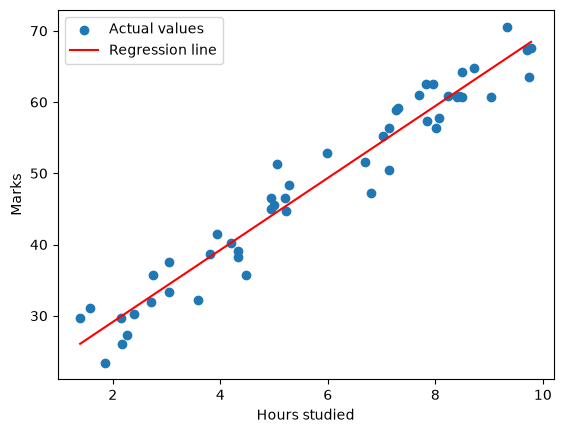

Slope: 5.053671158962768 Intercept: 19.02096457418247


In [44]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Sample data: hours studied vs marks
rng = np.random.default_rng(42)
X = rng.uniform(1, 10, 50).reshape(-1, 1)
y = 5 * X.ravel() + 20 + rng.normal(0, 4, 50)

model = LinearRegression().fit(X, y)
line = model.predict(np.sort(X, axis=0))

plt.scatter(X, y, label="Actual values")
plt.plot(np.sort(X, axis=0), line, color="red", label="Regression line")
plt.xlabel("Hours studied")
plt.ylabel("Marks")
plt.legend()
plt.show()

print("Slope:", model.coef_[0], "Intercept:", model.intercept_)

In [45]:
import pandas as pd

df = pd.read_csv("/home/thinkpad/Documents/BrototypeStudying/paper_three/Paper3/data/data.csv")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           12 non-null     int64  
 1   location     12 non-null     str    
 2   bedrooms     10 non-null     float64
 3   sq_ft        11 non-null     float64
 4   price_lakhs  11 non-null     float64
 5   age_years    12 non-null     int64  
dtypes: float64(3), int64(2), str(1)
memory usage: 708.0 bytes


In [46]:
df.head(5)

,id,location,bedrooms,sq_ft,price_lakhs,age_years
0,1,Kochi - Kakkanad,3.0,1450.0,65.5,2
1,2,Kochi - Edappally,2.0,1100.0,45.0,5
2,3,Trivandrum - Technopark,3.0,NaN,80.0,1
3,4,Kochi - Kakkanad,4.0,2200.0,120.0,0
4,5,Kochi - Palarivattom,NaN,950.0,55.0,8


In [47]:
df.tail(5)

,id,location,bedrooms,sq_ft,price_lakhs,age_years
7,8,Kochi - Kakkanad,3.0,1400.0,NaN,4
8,9,Kochi - Infopark,2.0,50000.0,45.0,2
9,10,Trivandrum - Pattom,3.0,1350.0,70.0,6
10,11,Calicut - Beach Road,NaN,1600.0,95.0,4
11,12,Kochi - Edappally,2.0,1050.0,42.0,7


In [48]:
df.duplicated().sum()

np.int64(0)

In [49]:
df.isnull().sum()

id             0
location       0
bedrooms       2
sq_ft          1
price_lakhs    1
age_years      0
dtype: int64

In [50]:
df = df.dropna(subset=["price_lakhs"])

In [51]:
df["sq_ft"].median()

np.float64(1400.0)

In [52]:
df["sq_ft"] = df["sq_ft"].fillna(df["sq_ft"].median())

In [53]:
df["bedrooms"].median()

np.float64(3.0)

In [54]:
df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].median())

In [55]:
df.describe()

,id,bedrooms,sq_ft,price_lakhs,age_years
count,11.000000,11.000000,11.000000,11.000000,11.000000
mean,6.363636,2.909091,6054.545455,91.454545,4.363636
std,3.748939,0.943880,14609.987244,89.349442,3.139195
min,1.000000,2.000000,950.000000,38.500000,0.000000
25%,3.500000,2.000000,1075.000000,45.000000,2.000000
50%,6.000000,3.000000,1400.000000,65.500000,4.000000
75%,9.500000,3.000000,1900.000000,87.500000,6.500000
max,12.000000,5.000000,50000.000000,350.000000,10.000000


In [56]:
number_col = df.select_dtypes(include="number")

In [57]:
number_col.columns

Index(['id', 'bedrooms', 'sq_ft', 'price_lakhs', 'age_years'], dtype='str')

{'whiskers': [<matplotlib.lines.Line2D at 0x78cc42281b10>,
 'caps': [<matplotlib.lines.Line2D at 0x78cc42282d10>,
 'boxes': [<matplotlib.lines.Line2D at 0x78cc42281350>],
 'medians': [<matplotlib.lines.Line2D at 0x78cc42283b10>],
 'fliers': [<matplotlib.lines.Line2D at 0x78cc42290290>],
 'means': []}

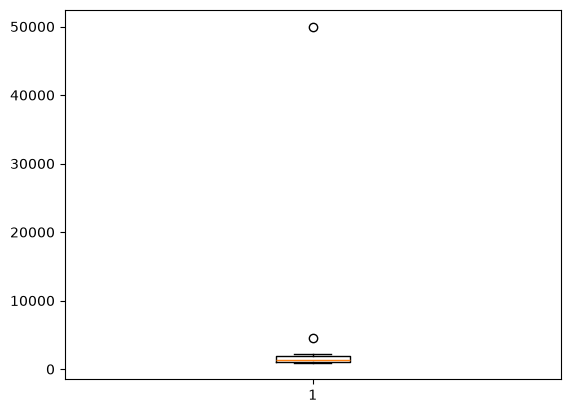

In [58]:
import matplotlib.pyplot as plt

plt.boxplot(df["sq_ft"])

In [59]:
Q1 = df["price_lakhs"].quantile(.25)
Q3 = df["price_lakhs"].quantile(.75)

IQR = Q3 -Q1

lowerbound = Q1 - 1.5 * IQR
upperbound = Q1 + 1.5 * IQR

outlier = df[(df["price_lakhs"] < lowerbound ) | (df["price_lakhs"] > upperbound)]
print(outlier)

   id              location  bedrooms   sq_ft  price_lakhs  age_years
3   4      Kochi - Kakkanad       4.0  2200.0        120.0          0
5   6  Trivandrum - Kowdiar       5.0  4500.0        350.0          3


In [60]:
def outlierDectection(data, colums):
    for col in colums:
        
        Q1 = data[col].quantile(.25)
        Q3 = data[col].quantile(.75)
        
        IQR = Q3 - Q1
        
        lowerbound = Q1 - 1.5 * IQR
        upperbound = Q3 + 1.5 * IQR
        
        outlier = data[(data[col] < lowerbound) | (data[col] > upperbound)]
        
        return outlier

In [61]:
Q1 = df["sq_ft"].quantile(.25)
Q3 = df["sq_ft"].quantile(.75)

IQR = Q3 -Q1

lowerbound = Q1 - 1.5 * IQR
upperbound = Q1 + 1.5 * IQR

outlier = df[(df["sq_ft"] < lowerbound ) | (df["sq_ft"] > upperbound)]

print(outlier)

   id              location  bedrooms    sq_ft  price_lakhs  age_years
5   6  Trivandrum - Kowdiar       5.0   4500.0        350.0          3
8   9      Kochi - Infopark       2.0  50000.0         45.0          2


In [62]:
outlierDectection(df,["sq_ft"])

,id,location,bedrooms,sq_ft,price_lakhs,age_years
5,6,Trivandrum - Kowdiar,5.0,4500.0,350.0,3
8,9,Kochi - Infopark,2.0,50000.0,45.0,2


In [63]:
median = df.loc[df["sq_ft"] < 5000, "sq_ft"].median()

df.loc[df["sq_ft"] > 5000, "sq_ft"] = median

{'whiskers': [<matplotlib.lines.Line2D at 0x78cc422e4b90>,
 'caps': [<matplotlib.lines.Line2D at 0x78cc422e5d50>,
 'boxes': [<matplotlib.lines.Line2D at 0x78cc422e4310>,
 'medians': [<matplotlib.lines.Line2D at 0x78cc422e6cd0>,
 'fliers': [<matplotlib.lines.Line2D at 0x78cc422e7490>,
 'means': []}

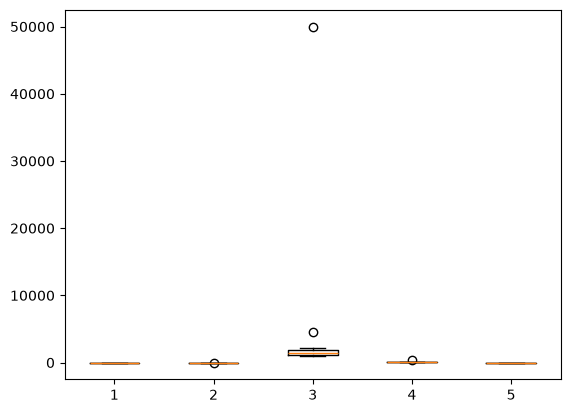

In [64]:
plt.boxplot(number_col)

In [65]:
number_col.columns

Index(['id', 'bedrooms', 'sq_ft', 'price_lakhs', 'age_years'], dtype='str')

{'whiskers': [<matplotlib.lines.Line2D at 0x78cc42190390>,
 'caps': [<matplotlib.lines.Line2D at 0x78cc42191590>,
 'boxes': [<matplotlib.lines.Line2D at 0x78cc4217fad0>],
 'medians': [<matplotlib.lines.Line2D at 0x78cc421924d0>],
 'fliers': [<matplotlib.lines.Line2D at 0x78cc42192c90>],
 'means': []}

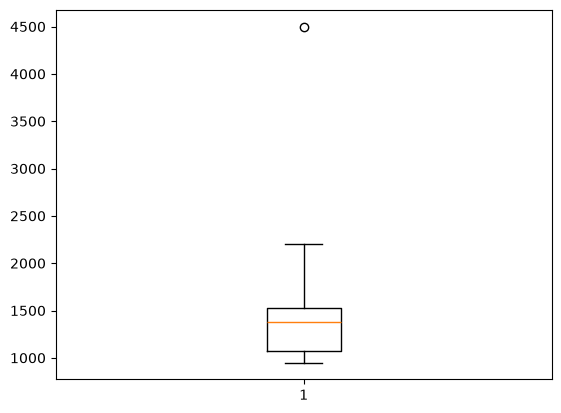

In [66]:
plt.boxplot(df["sq_ft"])

In [67]:
df.info()

<class 'pandas.DataFrame'>
Index: 11 entries, 0 to 11
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           11 non-null     int64  
 1   location     11 non-null     str    
 2   bedrooms     11 non-null     float64
 3   sq_ft        11 non-null     float64
 4   price_lakhs  11 non-null     float64
 5   age_years    11 non-null     int64  
dtypes: float64(3), int64(2), str(1)
memory usage: 616.0 bytes


In [68]:
df.head(5)

,id,location,bedrooms,sq_ft,price_lakhs,age_years
0,1,Kochi - Kakkanad,3.0,1450.0,65.5,2
1,2,Kochi - Edappally,2.0,1100.0,45.0,5
2,3,Trivandrum - Technopark,3.0,1400.0,80.0,1
3,4,Kochi - Kakkanad,4.0,2200.0,120.0,0
4,5,Kochi - Palarivattom,3.0,950.0,55.0,8


In [69]:
df = df.drop(columns="id")

In [70]:
df.info()

<class 'pandas.DataFrame'>
Index: 11 entries, 0 to 11
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   location     11 non-null     str    
 1   bedrooms     11 non-null     float64
 2   sq_ft        11 non-null     float64
 3   price_lakhs  11 non-null     float64
 4   age_years    11 non-null     int64  
dtypes: float64(3), int64(1), str(1)
memory usage: 528.0 bytes


In [71]:
df["price_lakhs"] = df["price_lakhs"].astype(str).str.replace("[^0-9,]", "", regex=True)
df["price_lakhs"] = df["price_lakhs"].astype(float)

In [72]:
df["city"] = df["location"].str.split(" - ").str[0].str.strip()

In [73]:
df.head(5)

,location,bedrooms,sq_ft,price_lakhs,age_years,city
0,Kochi - Kakkanad,3.0,1450.0,655.0,2,Kochi
1,Kochi - Edappally,2.0,1100.0,450.0,5,Kochi
2,Trivandrum - Technopark,3.0,1400.0,800.0,1,Trivandrum
3,Kochi - Kakkanad,4.0,2200.0,1200.0,0,Kochi
4,Kochi - Palarivattom,3.0,950.0,550.0,8,Kochi


In [74]:
df = df.drop(columns="location")

In [75]:
catCol = df.select_dtypes(include=["object", "category"]).columns

In [76]:
catCol

Index(['city'], dtype='str')

In [77]:
df = pd.get_dummies(df, columns=catCol, dtype=int, drop_first=True)

In [78]:
corr = df.corr(numeric_only=True)

In [79]:
corr

,bedrooms,sq_ft,price_lakhs,age_years,city_Kochi,city_Trivandrum
bedrooms,1.000000,0.868755,0.878583,-0.460218,-0.295084,0.515491
sq_ft,0.868755,1.000000,0.988318,-0.406681,-0.317386,0.496020
price_lakhs,0.878583,0.988318,1.000000,-0.319025,-0.377674,0.540640
age_years,-0.460218,-0.406681,-0.319025,1.000000,-0.133087,-0.210794
city_Kochi,-0.295084,-0.317386,-0.377674,-0.133087,1.000000,-0.670820
city_Trivandrum,0.515491,0.496020,0.540640,-0.210794,-0.670820,1.000000


<Axes: >

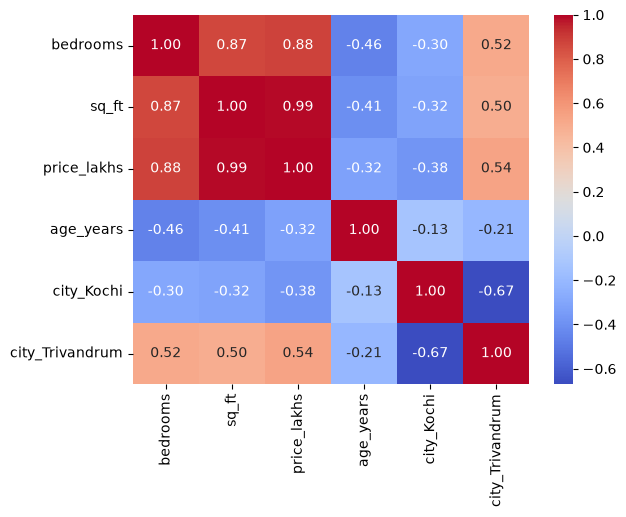

In [80]:
import seaborn as sns

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

In [81]:
df.columns

Index(['bedrooms', 'sq_ft', 'price_lakhs', 'age_years', 'city_Kochi',
       'city_Trivandrum'],
      dtype='str')

In [82]:
numCol = ['bedrooms', 'sq_ft', 'age_years']

In [83]:
x = df.drop(columns="price_lakhs")
y = df["price_lakhs"]

In [84]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=.20, random_state=42)

scaler = StandardScaler()

x_train[numCol] = scaler.fit_transform(x_train[numCol])
x_test[numCol] = scaler.transform(x_test[numCol])


In [85]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

model = LinearRegression()

model.fit(x_train, y_train)

y_pred = model.predict(x_test)
print(r2_score(y_test, y_pred))

0.5429849328266315


In [86]:
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import cross_val_score, KFold

model = LinearRegression()
# model = Lasso()
# model = Ridge()

kf = KFold(n_splits=2, shuffle=True, random_state=42)

scores = cross_val_score(model, x, y, cv=kf)

print(scores)
print(scores.mean())

[0.88238578 0.57029881]
0.7263422939283806


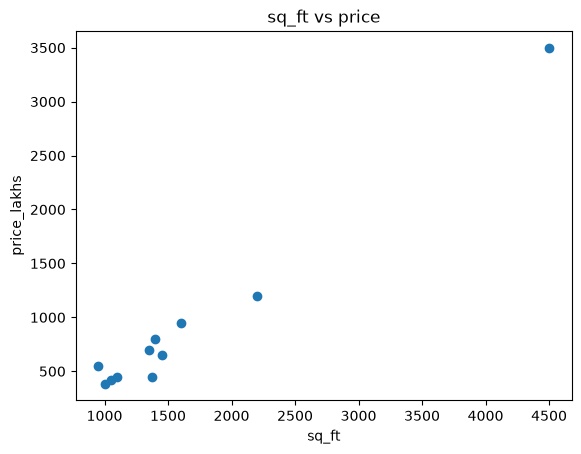

In [87]:
import matplotlib.pyplot as plt

# 1. Scatter plot: sq_ft vs price
plt.scatter(df["sq_ft"], df["price_lakhs"])
plt.xlabel("sq_ft")
plt.ylabel("price_lakhs")
plt.title("sq_ft vs price")
plt.show()

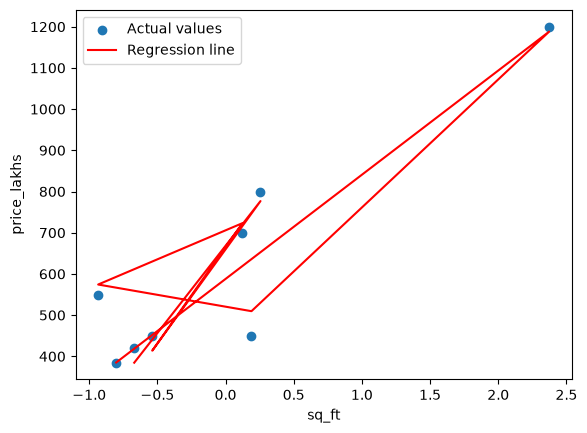

In [88]:
model = LinearRegression()
model.fit(x_train, y_train)               # this line was missing

y_pred_train = model.predict(x_train)

plt.scatter(x_train["sq_ft"], y_train, label="Actual values")
plt.plot(x_train["sq_ft"], y_pred_train, color="red", label="Regression line")
plt.xlabel("sq_ft")
plt.ylabel("price_lakhs")
plt.legend()
plt.show()

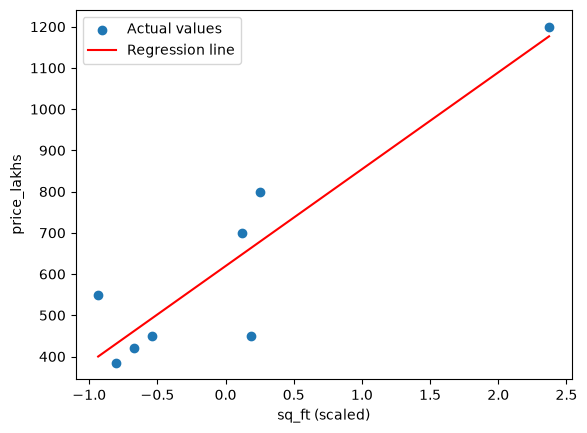

In [89]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

x_one = x_train[["sq_ft"]]                 # only one column, double brackets

line_model = LinearRegression()            # separate model just for this plot
line_model.fit(x_one, y_train)

y_line = line_model.predict(x_one)

order = x_one["sq_ft"].argsort()           # sort left to right

plt.scatter(x_one["sq_ft"], y_train, label="Actual values")
plt.plot(x_one["sq_ft"].iloc[order], y_line[order], color="red", label="Regression line")
plt.xlabel("sq_ft (scaled)")
plt.ylabel("price_lakhs")
plt.legend()
plt.show()

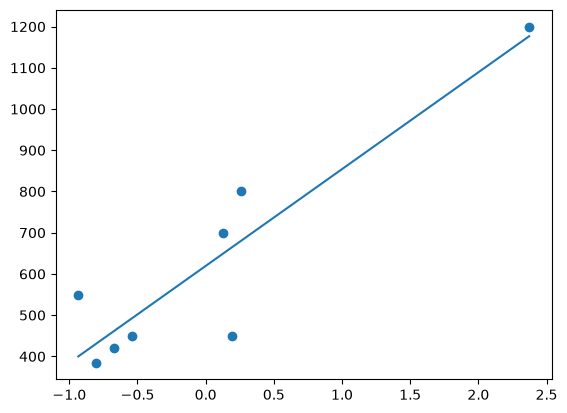

In [92]:
x_one = x_train[["sq_ft"]]
line_model = LinearRegression()
line_model.fit(x_one, y_train)
y_line = line_model.predict(x_one)
order = x_one["sq_ft"].argsort()

plt.scatter(x_one["sq_ft"], y_train)
plt.plot(x_one["sq_ft"].iloc[order], y_line[order])